# 04 Win probability model

**Objective.** Show the win probability model is accurate, calibrated, monotone and leak-free, because leverage is built on it.

**Inputs.** pressure/output, wp_model.joblib and tables written by pressure.wp_model.run.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import style
from common.io import read_parquet, read_table
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Step 1. Features and monotone constraints

In [2]:
from pressure import wp_model, plots as p2
pd.DataFrame(wp_model.FEATURES).fillna("").T

,balls_left,wkts_before,score_vs_par,comp_code,impact,runs_needed,rrr
1,1.0,-1.0,1.0,0.0,0.0,,
2,1.0,-1.0,,0.0,0.0,-1.0,-1.0


## Step 2. Grouped cross-validation metrics, out of fold by match

In [3]:
read_table("pressure", "wp_metrics.csv")

,innings,balls,auc,brier,log_loss,auc_raw,cal_slope,cal_intercept
0,1,100736,0.684361,0.223979,0.638592,0.684361,1.086193,0.00037
1,2,92558,0.896089,0.130631,0.405460,0.897788,0.983284,0.00011


## Step 3. Calibration curves

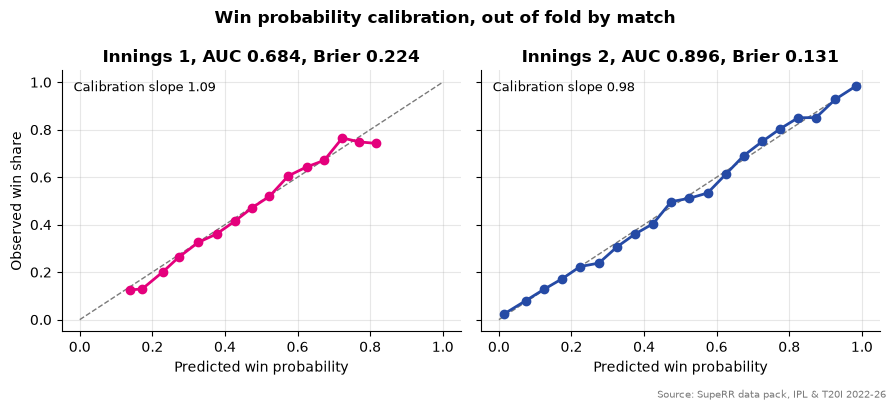

In [4]:
p2.calibration(); plt.show()

## Step 4. Calibration methods compared

In [5]:
read_table("pressure", "wp_calibrator_comparison.csv")

,innings,method,auc,brier,cal_slope
0,1,isotonic,0.676889,0.226081,0.897669
1,1,platt,0.679436,0.225500,0.950567
2,1,none,0.684361,0.223979,1.086193
3,2,isotonic,0.894362,0.131047,0.955345
4,2,platt,0.896089,0.130631,0.983284
5,2,none,0.897788,0.129877,0.824589


## Step 5. Why venue enters as a par on the score

In [6]:
read_table("pressure", "wp_inn1_ablation.csv")

,feature_set,oof_auc
0,"score, wickets, balls, crr",0.682923
1,plus raw venue index,0.644268
2,score scaled by venue par,0.685967
3,"par score without crr, used",0.686223


## Step 6. Monotonicity checks on the full surface

In [7]:
read_table("pressure", "wp_monotonic_checks.csv")

,feature,violations
0,runs_needed,0.0
1,wkts_before,0.0
2,balls_left at fixed need,0.0


## Step 7. Known situations

In [8]:
read_table("pressure", "wp_known_situations.csv").round(3)

,comp_type,balls_left,wkts_in_hand,runs_needed,rrr,wp_chasing
0,IPL,12,6,30,15.000,0.400
1,IPL,12,2,30,15.000,0.083
2,IPL,6,5,12,12.000,0.603
3,IPL,6,5,20,20.000,0.229
4,IPL,30,5,50,10.000,0.545
5,IPL,60,3,90,9.000,0.096
6,IPL,60,7,90,9.000,0.673
7,IPL,120,10,180,9.000,0.647
8,IPL,120,10,230,11.500,0.318
9,IPL,24,4,40,10.000,0.529


## Step 8. Chase curves

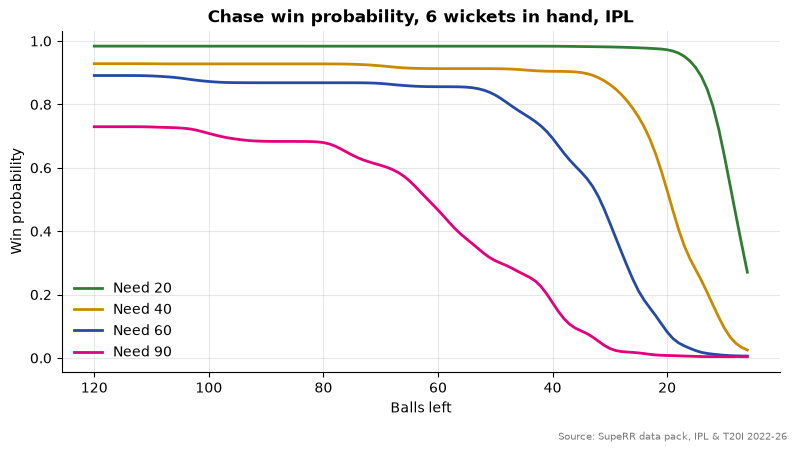

In [9]:
p2.wp_curves(); plt.show()

## Key findings

In [10]:
m = read_table("pressure", "wp_metrics.csv").set_index("innings")
k = read_table("pressure", "wp_known_situations.csv")
r = k[(k.comp_type == "IPL") & (k.balls_left == 12) & (k.wkts_in_hand == 6)]["wp_chasing"].iloc[0]
display(Markdown(f'''
- Chase model AUC {m.loc[2, "auc"]:.3f}, Brier {m.loc[2, "brier"]:.3f}, calibration slope {m.loc[2, "cal_slope"]:.2f}, inside every accuracy target.
- First innings AUC {m.loc[1, "auc"]:.3f}, inside the expected 0.68 to 0.72 band.
- Zero monotonicity violations across the grid.
- Needing 30 off 12 with 6 wickets in hand in the IPL gives the chase {r:.0%}.
'''))


- Chase model AUC 0.896, Brier 0.131, calibration slope 0.98, inside every accuracy target.
- First innings AUC 0.684, inside the expected 0.68 to 0.72 band.
- Zero monotonicity violations across the grid.
- Needing 30 off 12 with 6 wickets in hand in the IPL gives the chase 40%.


## Outputs written

pressure/output, wp_model.joblib and balls_wp.parquet, gitignored. Tables wp_metrics, wp_calibration, wp_known_situations, wp_monotonic_checks, wp_inn1_ablation, wp_calibrator_comparison. Figures 04_wp_calibration.png and 04_wp_curves.png.